# 12 · Incremental rates of profit

Notebooks 9–11 measure a sector's profitability by its **average** rate of profit, `r = S/(K+V)`, and estimate the capital-mobility coefficient `μ` against the gap between that rate and the country's mean. Notebook 9 found that these gaps persist for twenty years. Shaikh (*Capitalism*, 2016, ch. 7) argues that this is what competition predicts: what competition equalizes is the **incremental** rate of profit, the return on new investment, not the average rate on the whole stock. If `dΠᵢ/dKᵢ = r_I` in every sector, then `rᵢ = r_I + cᵢ/Kᵢ` for a sector-specific constant `cᵢ`, and average rates can differ forever (his footnote 29). Old capital of different vintages, and whatever the accounts happen to count as capital, earn what they earn; competition acts on the margin.

His measure (eq. 7.7) is the change in real gross profit over the previous year's real gross investment,

`r_I,t ≈ ΔΠ_t / I_{t−1}`.

It is very turbulent, so he smooths it (an HP filter in ch. 16; Christodoulopoulos 1995 uses three-year sums). This notebook puts the measure to the 26-country EU sectoral panel and asks two questions:

1. Do incremental rates equalize where average rates don't?
2. Does capital follow incremental-rate gaps rather than average-rate gaps?

`compute_incremental_panel`, `hp_filter` and `estimate_persistence` (`src/mobility_estimation.jl`) do the work.

In [1]:
include(joinpath("..", "..", "src", "MarxKapital.jl"))
using Plots, DataFrames, Statistics, Printf
gr(fmt = :png, size = (760, 420), margin = 3Plots.mm)

MarxKapital loaded. Type  model_help()  to get started.


Plots.GRBackend()

In [2]:
"""Weighted standard deviation of `x`."""
wsd(x, w) = (m = sum(w .* x) / sum(w); sqrt(sum(w .* (x .- m) .^ 2) / sum(w)))

"""
Standard deviation of the country × sector long-run mean gaps in `col`, net of
sampling noise: the variance of the unit means minus the mean of
(within-unit variance / years).
"""
function permanent_sd(P, col)
    m = combine(groupby(P, [:geo, :section]), col => mean => :m, col => var => :v, nrow => :T)
    m = m[m.T .>= 2, :]
    sqrt(max(var(m.m) - mean(m.v ./ m.T), 0.0))
end

"""Rows whose incremental gap is inside its 1st–99th percentiles."""
trim(P) = (b = quantile(P.gap_I, [0.01, 0.99]); P[b[1] .<= P.gap_I .<= b[2], :])

"""One-standard-deviation effect of a regressor, net of the fixed effects."""
sd_fe(P, x) = std(demean_fe(x, tuple.(P.geo, P.section), tuple.(P.geo, P.year)))

sd_fe (generic function with 1 method)

## 1. The panel

The 15 market sectors (all NACE sections except L, O, P, Q) of 26 EU countries, from `data/eurostat_eu_sectors.csv`. Gross profit is `Π = GVA − V` (compensation of employees; self-employed excluded, as in notebooks 9–11). Both flows are in real terms: `Π` is deflated by the sector's own GVA deflator (`GVA/GVA_volume`), and investment is gross fixed capital formation in chain-linked volumes (`GFCF_volume`). Chain-linked volumes don't add up across sectors, but every use here is a ratio within one sector.

The rate is backward-looking, so it can serve as a regressor: the row of year `t` carries the rate of `t−1`,

`r_I = (Π_{t−1} − Π_{t−1−w}) / Σ_{k=1..w} I_{t−1−k}`,

with `w` = 1 (Shaikh's measure) or `w` = 3 (three-year sums). Its gap `gap_I = 100(r_I − r̄_I)` is taken from the investment-weighted mean of the country-year, so it sums to zero like the average-rate gap. Rows whose lagged investment is not positive are dropped.

In [3]:
eu = CSV.read(joinpath("..", "..", "data", "eurostat_eu_sectors.csv"), DataFrame)
MARKET = setdiff(sort(String.(unique(eu.section))), ["L", "O", "P", "Q"])
inc1 = compute_incremental_panel(eu; sections = MARKET)               # one year, real
inc3 = compute_incremental_panel(eu; sections = MARKET, window = 3)   # three years, real
P1, P3 = inc1.panel, inc3.panel
qs = [0.01, 0.25, 0.5, 0.75, 0.99]
fmt(v) = join((@sprintf("%5.2f", x) for x in v), "  ")
@printf("quantiles             1%%    25%%    50%%    75%%    99%%\n")
@printf("average rate r       %s\n", fmt(quantile(P3.r, qs)))
@printf("r_I, one year        %s   (%d rows, %d dropped)\n", fmt(quantile(P1.rI, qs)), nrow(P1), inc1.dropped)
@printf("r_I, three years     %s   (%d rows, %d dropped)\n", fmt(quantile(P3.rI, qs)), nrow(P3), inc3.dropped)

quantiles             1%    25%    50%    75%    99%
average rate r       -0.04   0.05   0.12   0.21   0.86


r_I, one year        -1.88  -0.10   0.05   0.22   2.39   (10653 rows, 12 dropped)
r_I, three years     -0.91  -0.05   0.04   0.15   1.27   (9883 rows, 782 dropped)


The incremental rate is far more spread out than the average rate. With a one-year window the central half runs from −0.10 to 0.22 and the extreme percentiles from −1.9 to 2.4: a sector's gross profit commonly moves by more in a year than it invested the year before. Three-year sums halve the spread (1st–99th percentiles −0.91 to 1.27) at the cost of 782 rows.

## 2. Dispersion over time

The cross-sector dispersion within each country (the standard deviation weighted by capital for the average rate and by lagged investment for the incremental rate), then the median over countries, by the year the rate refers to. The HP-smoothed series (`λ` = 100, per country × sector) is two-sided: it uses future data and is shown for comparison only, never used as a regressor.

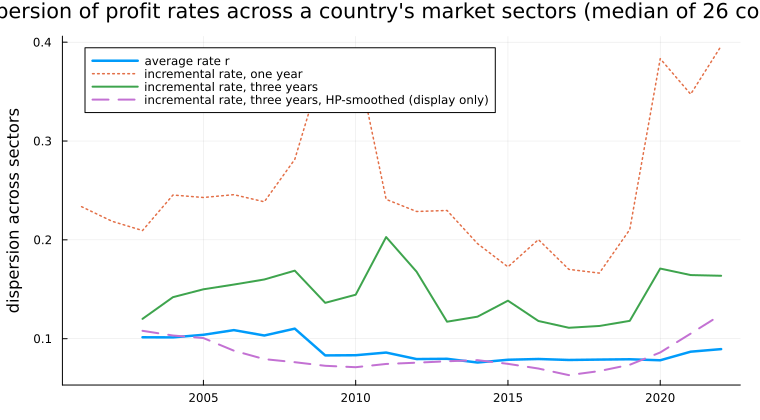

In [4]:
for P in (P1, P3)
    P.rI_hp = similar(P.rI)
    for g in groupby(P, [:geo, :section])
        g.rI_hp .= hp_filter(g.rI; λ = 100)
    end
end
"""Median over countries of the cross-sector dispersion of `col` (weights `w`), by the year the rate refers to."""
function by_year(P, col, w)
    d = combine(groupby(P, [:geo, :year]), [col, w] => ((x, v) -> wsd(x, v)) => :sd)
    y = combine(groupby(d, :year), :sd => median => :sd, nrow => :countries)
    y.year .-= 1
    sort(y[y.countries .>= 20, :], :year)
end
A, B1, B3, H = by_year(P3, :r, :K), by_year(P1, :rI, :I_lag), by_year(P3, :rI, :I_lag), by_year(P3, :rI_hp, :I_lag)
plot(A.year, A.sd; lw = 2.5, label = "average rate r", ylabel = "dispersion across sectors",
     title = "Dispersion of profit rates across a country's market sectors (median of 26 countries)")
plot!(B1.year, B1.sd; lw = 1.5, ls = :dot, label = "incremental rate, one year")
plot!(B3.year, B3.sd; lw = 2, label = "incremental rate, three years")
plot!(H.year, H.sd; lw = 2, ls = :dash, label = "incremental rate, three years, HP-smoothed (display only)")

In [5]:
@printf("median over the years: average %.3f | incremental one year %.3f, three years %.3f, HP-smoothed %.3f\n",
        median(A.sd), median(B1.sd), median(B3.sd), median(H.sd))

median over the years: average 0.083 | incremental one year 0.236, three years 0.143, HP-smoothed 0.077


The raw incremental rate is about three times as dispersed as the average rate (a median over the years of 0.236 against 0.083), and three-year sums still leave it 0.143. Only after HP smoothing does it fall to the average rate's level (0.077). So incremental rates are not visibly more equal than average rates: whatever equalization there is would have to show in the *persistent* part of the gaps, which is the next question. The one-year series also jumps in 2009–2010 and 2020–2022, when gross profit fell and recovered by large amounts relative to investment.

## 3. Persistence

Shaikh's claim is about the long run: incremental gaps should be transitory, average gaps may be permanent. The persistence-of-profits regression (Mueller; Vaona 2011–2013) separates the two:

`gapᵢₜ = aᵢ + ρ·gapᵢ,ₜ₋₁ + uᵢₜ`,

with a fixed effect `aᵢ` for each country × sector. `estimate_persistence` reports `ρ`, the share of the gap's variance due to the country × sector effects (the *between* share), and each unit's long-run position `aᵢ/(1 − ρ)`. The table also gives the dispersion of the long-run mean gaps net of sampling noise (`permanent_sd`: the variance of the unit means minus the mean of within-unit variance over years), which doesn't depend on `ρ`. "Trimmed" drops rows outside the 1st–99th percentiles of `gap_I`. With about 20 years per unit the Nickell bias in `ρ` is of order −(1 + ρ)/T ≈ −0.05 to −0.1.

In [6]:
@printf("%-12s %-9s │ %6s %6s │ %8s %8s │ %9s %9s\n", "window", "sample", "ρ avg", "ρ inc", "betw avg", "betw inc", "perm avg", "perm inc")
for (w, P) in (("one year", P1), ("three years", P3)), (s, Q) in (("all rows", P), ("trimmed", trim(P)))
    a, b = estimate_persistence(Q, :gap), estimate_persistence(Q, :gap_I)
    @printf("%-12s %-9s │ %6.2f %6.2f │ %8.2f %8.2f │ %6.1f pp %6.1f pp\n", w, s, a.ρ, b.ρ,
            a.between_share, b.between_share, permanent_sd(Q, :gap), permanent_sd(Q, :gap_I))
end

window       sample    │  ρ avg  ρ inc │ betw avg betw inc │  perm avg  perm inc


one year     all rows  │   0.82  -0.14 │     0.74     0.04 │   15.1 pp    0.0 pp


one year     trimmed   │   0.85  -0.01 │     0.76     0.06 │   14.7 pp    6.0 pp


three years  all rows  │   0.81   0.07 │     0.76     0.07 │   14.7 pp   26.2 pp


three years  trimmed   │   0.82   0.53 │     0.78     0.14 │   14.3 pp    8.0 pp


**Average-rate gaps are mostly permanent.** `ρ` is 0.81–0.85 in every column, three quarters of their variance (0.74–0.78) is between country × sector units, and the noise-corrected dispersion of the long-run positions is 14–15 pp. This is notebook 9's finding.

**Incremental-rate gaps are mostly transitory, as Shaikh says.** Only 4–14% of their variance is between units, and with a one-year window they have no persistence at all (`ρ` = −0.14 on all rows, −0.01 trimmed). Three-year sums create persistence mechanically (consecutive windows overlap in two of their three years), hence `ρ` = 0.53 trimmed. Untrimmed, a few extreme rates dominate: the noise correction removes all permanent dispersion at one year (0.0 pp) and leaves an implausible 26.2 pp at three years. On the trimmed rows the permanent dispersion of incremental gaps is 6.0–8.0 pp, about half that of average gaps.

So **incremental rates are not equalized either**, but they are less unequal in the long run than average rates. The scatter shows each country × sector's long-run mean gap on both measures (trimmed three-year rates, units with at least ten years).

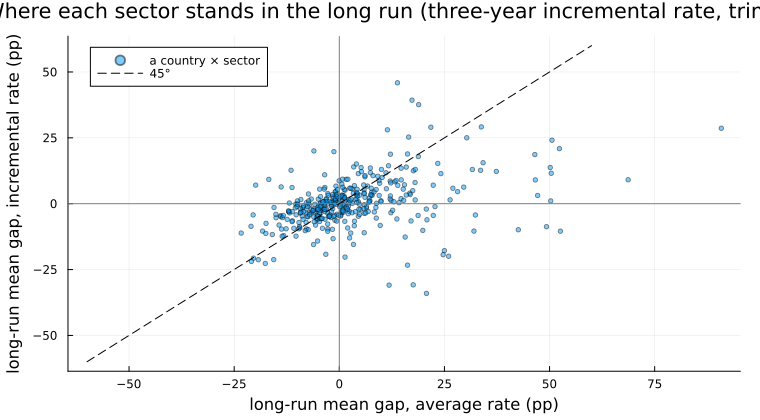

In [7]:
T3 = trim(P3)
m = combine(groupby(T3, [:geo, :section]), :gap => mean => :average, :gap_I => mean => :incremental, nrow => :T)
m = m[m.T .>= 10, :]
scatter(m.average, m.incremental; ms = 2.5, alpha = 0.5, label = "a country × sector",
        xlabel = "long-run mean gap, average rate (pp)", ylabel = "long-run mean gap, incremental rate (pp)",
        title = "Where each sector stands in the long run (three-year incremental rate, trimmed)")
hline!([0]; color = :gray, label = ""); vline!([0]; color = :gray, label = "")
plot!(-60:60, -60:60; color = :black, ls = :dash, label = "45°")

In [8]:
@printf("%d units; correlation of the two long-run positions %.2f; sd average %.1f pp, incremental %.1f pp\n",
        nrow(m), cor(m.average, m.incremental), std(m.average), std(m.incremental))

390 units; correlation of the two long-run positions 0.40; sd average 14.4 pp, incremental 9.5 pp


The two long-run positions are correlated (0.40): sectors with a high average rate also tend to earn more on new investment. The incremental positions are more compressed (sd 9.5 pp against 14.4 pp, before the noise correction), and the sectors with the highest average rates, on the right, mostly sit far below the 45° line, as footnote 29 would have it. But there is no sign of the flat line at zero that full equalization of incremental rates would produce.

## 4. Does capital follow the incremental gap?

First the fixed-share net transfer of notebooks 9 and 10, `y = 100(GFCF − σ̄ S)/C`, with country × sector and country-year effects and country-clustered errors, against each gap and both. Then a check on the incremental rate's denominator: high investment in the window raises the denominator and so lowers `r_I` mechanically.

In [9]:
for (lab, X) in (("average gap", T3.gap), ("incremental gap", T3.gap_I), ("both", hcat(T3.gap, T3.gap_I)))
    e = estimate_fe_ols(T3, T3.y, X)
    @printf("y on %-16s %s\n", lab, join((@sprintf("%7.4f (se %.4f)", e.β[k], e.se_cluster[k]) for k in eachindex(e.β)), "   "))
end
# the denominator: in current prices, so that investment and capital are in the same units
N3 = trim(compute_incremental_panel(eu; sections = MARKET, window = 3, real = false).panel)
e = estimate_fe_ols(N3, N3.gap_I, 100 .* N3.I_lag ./ N3.K)
@printf("incremental gap on the investment of the three years before (%% of capital): %.3f (se %.3f)\n", e.β[1], e.se_cluster[1])

y on average gap      -0.0968 (se 0.0193)
y on incremental gap  -0.0143 (se 0.0044)


y on both             -0.0929 (se 0.0202)   -0.0039 (se 0.0045)
incremental gap on the investment of the three years before (% of capital): -0.420 (se 0.066)


Both gaps carry the negative sign of notebook 10, which comes from the fixed reinvestment share, not from capital fleeing profit (notebook 11). The incremental gap's coefficient is a seventh of the average gap's (−0.014 against −0.097) and loses significance when both enter (−0.004, se 0.0045), while the average gap's is unchanged (−0.093). The denominator bias is large: one percentage point more investment over the three years, as a share of capital, lowers the incremental gap by 0.42 pp (se 0.066). A regression of investment on `gap_I` therefore has a built-in negative feedback from past investment, which biases `μ` towards zero whenever investment is persistent.

## 5. The investment function

The better test uses notebook 11's investment function at `η` = 1, the elasticity it calibrated:

`gk = λ · σ̄ᵢ · (r̄/rᵢ) · sk + μ · gap + country × sector + country-year`,

on notebook 11's sample (rows with `r/r̄` in [1/3, 3]), joined with the trimmed three-year incremental panel. The one-sd effects are the coefficient times the standard deviation of the gap net of the fixed effects, in percentage points of capital.

In [10]:
IP = compute_investment_panel(eu; sections = MARKET)
"""Trimmed three-year incremental panel joined with the investment panel, inside r/r̄ ∈ [1/3, 3] (notebook 11's sample)."""
function joint(raw; window = 3, real = true, self_employed = :excluded, countries = nothing)
    P = trim(compute_incremental_panel(raw; sections = MARKET, window, real, self_employed, countries).panel)
    I = compute_investment_panel(raw; sections = MARKET, self_employed, countries)
    J = innerjoin(P, select(I, :geo, :section, :year, :gk, :sk, :rbar, :σbar, :valid); on = [:geo, :section, :year])
    J[J.valid .& (1/3 .<= J.r ./ J.rbar .<= 3), :]
end
"""The investment function at η = 1 with the average gap, the incremental gap, or both."""
function investment_fit(J)
    s = J.σbar .* (J.rbar ./ J.r) .* J.sk
    a = estimate_fe_ols(J, J.gk, hcat(s, J.gap))
    b = estimate_fe_ols(J, J.gk, hcat(s, J.gap_I))
    c = estimate_fe_ols(J, J.gk, hcat(s, J.gap, J.gap_I))
    sA, sI = sd_fe(J, J.gap), sd_fe(J, J.gap_I)
    (n = nrow(J), μ_average = a.β[2], se_average = a.se_cluster[2], μ_incremental = b.β[2], se_incremental = b.se_cluster[2],
     both_average = c.β[2], both_se_average = c.se_cluster[2], both_incremental = c.β[3], both_se_incremental = c.se_cluster[3],
     sd_effect_average = a.β[2] * sA, sd_effect_incremental = b.β[2] * sI)
end
J = joint(eu)
f = investment_fit(J)
@printf("%d rows\n", f.n)
@printf("average gap alone      μ = %.3f (se %.3f); one sd of the gap moves investment by %.2f pp of capital\n", f.μ_average, f.se_average, f.sd_effect_average)
@printf("incremental gap alone  μ = %.4f (se %.4f); one sd: %.2f pp\n", f.μ_incremental, f.se_incremental, f.sd_effect_incremental)
@printf("both                   average %.3f (se %.3f), incremental %.4f (se %.4f)\n", f.both_average, f.both_se_average, f.both_incremental, f.both_se_incremental)

6951 rows
average gap alone      μ = 0.143 (se 0.032); one sd of the gap moves investment by 0.67 pp of capital


incremental gap alone  μ = 0.0117 (se 0.0045); one sd: 0.23 pp
both                   average 0.142 (se 0.035), incremental 0.0012 (se 0.0054)


**Capital follows the average-rate gap.** Alone, its `μ` is 0.143 (se 0.032), close to notebook 11's 0.13 on a slightly different sample, and one standard deviation of the gap moves investment by 0.67 pp of capital. The incremental gap alone is significant too (0.0117, se 0.0045) but moves investment by only 0.23 pp per sd, a third as much. **In the horse race the incremental gap adds nothing**: its coefficient drops to 0.0012 (se 0.0054), while the average gap's stays at 0.142.

## 6. Robustness

The same three fits for Shaikh's one-year window, nominal flows (deflating neither `Π` nor investment), self-employed income imputed at the average employee's compensation, the panel without Ireland and Luxembourg (whose sectoral accounts are dominated by multinationals' profit shifting), and the years up to 2008 and from 2009.

In [11]:
cases = [("baseline: three years, real", J),
         ("one-year window", joint(eu; window = 1)),
         ("current prices", joint(eu; real = false)),
         ("self-employed imputed", joint(eu; self_employed = :imputed)),
         ("without IE and LU", joint(eu; countries = setdiff(sort(unique(String.(eu.geo))), ["IE", "LU"]))),
         ("up to 2008", J[J.year .<= 2008, :]),
         ("2009 on", J[J.year .>= 2009, :])]
@printf("%-28s %5s │ %15s │ %17s │ %17s │ %5s %5s\n", "", "n", "average alone", "incremental alone", "incremental, both", "1sd A", "1sd I")
for (lab, Jc) in cases
    f = investment_fit(Jc)
    @printf("%-28s %5d │ %6.3f (%5.3f) │ %7.4f (%6.4f) │ %7.4f (%6.4f) │ %5.2f %5.2f\n", lab, f.n, f.μ_average, f.se_average,
            f.μ_incremental, f.se_incremental, f.both_incremental, f.both_se_incremental, f.sd_effect_average, f.sd_effect_incremental)
end

                                 n │   average alone │ incremental alone │ incremental, both │ 1sd A 1sd I
baseline: three years, real   6951 │  0.143 (0.032) │  0.0117 (0.0045) │  0.0012 (0.0054) │  0.67  0.23


one-year window               7457 │  0.126 (0.038) │  0.0026 (0.0017) │ -0.0005 (0.0018) │  0.62  0.10
current prices                6960 │  0.148 (0.031) │  0.0106 (0.0039) │ -0.0031 (0.0043) │  0.69  0.22


self-employed imputed         5643 │  0.156 (0.031) │  0.0070 (0.0052) │ -0.0025 (0.0048) │  0.60  0.14
without IE and LU             6495 │  0.133 (0.034) │  0.0153 (0.0040) │  0.0061 (0.0038) │  0.59  0.29


up to 2008                    2708 │  0.064 (0.057) │  0.0097 (0.0060) │  0.0052 (0.0058) │  0.24  0.16
2009 on                       4243 │  0.203 (0.046) │  0.0125 (0.0053) │ -0.0048 (0.0087) │  0.74  0.23


The average gap's coefficient is 0.13–0.16 in every full-sample variant and 0.20 from 2009; it is small and insignificant only up to 2008 (0.064, se 0.057), as in notebook 11. The incremental gap alone is never more than about 0.015 and never moves investment by more than 0.29 pp per sd, against 0.59–0.74 pp for the average gap outside the pre-2008 years. With both in, the incremental gap is insignificant everywhere (−0.0048 to 0.0061, all within 1.6 se of zero). With Shaikh's own one-year window it is insignificant even alone (0.0026, se 0.0017).

## 7. What it means for the model

In the model each department has one technique with constant returns: profits, wages and capital all scale with the department's size. Its marginal and average rates of profit are therefore the same, `rᵢ = Sᵢ/(Cᵢ+Vᵢ)`, and the distinction Shaikh draws can't arise inside it. What the model's mobility term `μ·(rᵢ − r̄)·Cᵢ` needs from the data is the rate that capital actually responds to, and on this panel that is the average rate. The mobility term keeps it.

The persistent part of the average gaps (14–15 pp) is what footnote 29 explains: vintages of capital and differences in what the accounts measure as capital (land, intangibles, the self-employed, the treatment of dwellings). In the estimates of notebooks 9–12 it is absorbed by the country × sector effects, so `μ` is identified from the *changes* in the average gaps, not from their levels. When the model is calibrated, the permanent gaps belong in the calibrated technique of each department (its `k` and `e`), not in a disequilibrium that `μ` is supposed to close.

## What the panel says about incremental rates

- **Incremental rates are mostly transitory, as Shaikh argues.** Only 4–14% of the variance of their gaps is between country × sector units, against 74–78% for average rates; with a one-year window they have no persistence (`ρ` ≈ 0).
- **But they are not equalized.** Their permanent dispersion, net of noise, is 6–8 pp (trimmed), about half that of average rates (14–15 pp), and the two long-run positions are correlated (0.40).
- **They are extremely noisy:** raw dispersion three times that of average rates, and a mechanical denominator bias (one point more past investment lowers the gap by 0.42 pp).
- **Capital follows the average-rate gap** (`μ` = 0.14 at `η` = 1, robust from 0.13 to 0.20 outside the pre-2008 years). The incremental gap moves investment a third as much per sd alone and adds nothing once the average gap is in.
- **The model keeps the average rate** in its mobility term. Inside a department marginal and average rates coincide; the persistent average gaps in the data belong in each department's calibrated technique.